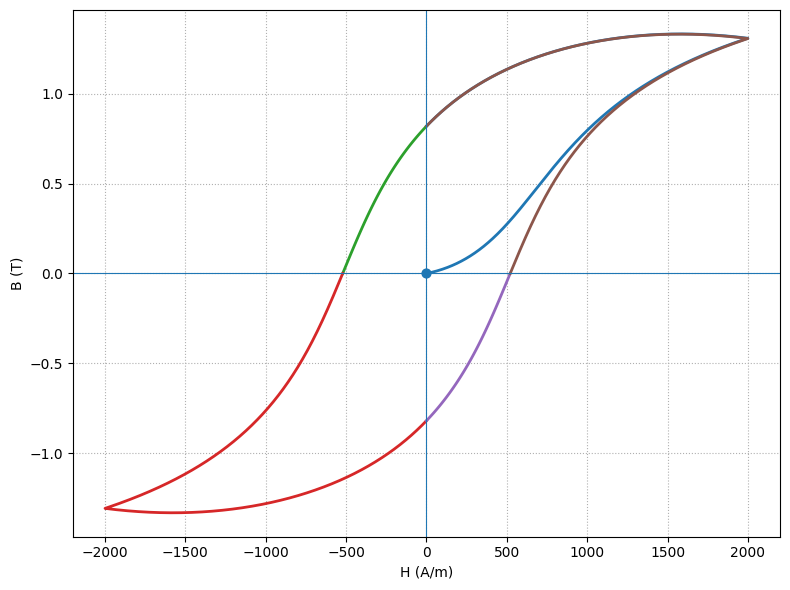

In [3]:
import numpy as np
import matplotlib.pyplot as plt

MU0 = 4.0 * np.pi * 1.0e-7

# Material: Fe-0.8 wt%C steel
# Source: parameters reported in:
# Etien, Halbert, Poinot - "An Improved Jiles-Atherton Model..."
# (citing Jiles, Thoelke, Devine, 1992)
MS = 1.6e6
A_PARAM = 1000.0
K_PARAM = 700.0
ALPHA = 1.4e-3
C_PARAM = 0.22


def langevin(x):
    """Return the Langevin function L(x) = coth(x) - 1/x."""
    y = np.empty_like(x, dtype=float)

    small = np.abs(x) < 1.0e-4
    large = ~small

    y[small] = x[small] / 3.0 - (x[small] ** 3) / 45.0 + (2.0 * x[small] ** 5) / 945.0
    y[large] = 1.0 / np.tanh(x[large]) - 1.0 / x[large]

    return y


def solve_anhysteretic_magnetization(h_value, mirr_value, m_previous, max_iter=80, tol=1.0e-9):
    """
    Solve the anhysteretic magnetization using fixed-point iteration.
    Returns:
        ma_value: anhysteretic magnetization
        m_total: total magnetization estimate
    """
    m_estimate = m_previous

    for _ in range(max_iter):
        h_effective = h_value + ALPHA * m_estimate
        x_value = np.array([h_effective / A_PARAM], dtype=float)
        ma_value = MS * langevin(x_value)[0]

        m_total = C_PARAM * ma_value + (1.0 - C_PARAM) * mirr_value

        if abs(m_total - m_estimate) < tol * MS:
            m_estimate = m_total
            break

        m_estimate = m_total

    return ma_value, m_estimate


def simulate_jiles_atherton(h_values, m0=0.0):
    """
    Scalar, quasi-static Jiles-Atherton simulation.
    This is a simple educational implementation.
    """
    h_values = np.asarray(h_values, dtype=float)

    mirr = np.zeros_like(h_values)
    ma = np.zeros_like(h_values)
    m_total = np.zeros_like(h_values)
    b_values = np.zeros_like(h_values)

    mirr[0] = m0
    ma[0], m_total[0] = solve_anhysteretic_magnetization(h_values[0], mirr[0], m0)
    b_values[0] = MU0 * (h_values[0] + m_total[0])

    for i in range(1, len(h_values)):
        h_now = h_values[i]
        h_prev = h_values[i - 1]
        delta_h = h_now - h_prev

        if delta_h >= 0.0:
            delta = 1.0
        else:
            delta = -1.0

        ma_temp, _ = solve_anhysteretic_magnetization(h_now, mirr[i - 1], m_total[i - 1])

        denominator = K_PARAM * delta - ALPHA * (ma_temp - mirr[i - 1])
        dmirr_dh = (ma_temp - mirr[i - 1]) / denominator

        mirr[i] = mirr[i - 1] + dmirr_dh * delta_h

        ma[i], m_total[i] = solve_anhysteretic_magnetization(h_now, mirr[i], m_total[i - 1])
        b_values[i] = MU0 * (h_now + m_total[i])

    return {
        "H": h_values,
        "M": m_total,
        "Mirr": mirr,
        "Man": ma,
        "B": b_values,
    }


def find_axis_crossings(h_values, b_values):
    """
    Find crossings of H=0 or B=0 and insert interpolated points.
    Returns lists of segments separated at each crossing.
    """
    points_h = [h_values[0]]
    points_b = [b_values[0]]

    n_points = len(h_values)

    for i in range(n_points - 1):
        h1 = h_values[i]
        h2 = h_values[i + 1]
        b1 = b_values[i]
        b2 = b_values[i + 1]

        crossings = []

        # Crossing H = 0
        if h1 * h2 < 0.0:
            t_h = -h1 / (h2 - h1)
            b_cross = b1 + t_h * (b2 - b1)
            crossings.append((t_h, 0.0, b_cross))

        # Crossing B = 0
        if b1 * b2 < 0.0:
            t_b = -b1 / (b2 - b1)
            h_cross = h1 + t_b * (h2 - h1)
            crossings.append((t_b, h_cross, 0.0))

        crossings.sort(key=lambda item: item[0])

        for _, h_cross, b_cross in crossings:
            points_h.append(h_cross)
            points_b.append(b_cross)

        points_h.append(h2)
        points_b.append(b2)

    segments_h = []
    segments_b = []

    current_h = [points_h[0]]
    current_b = [points_b[0]]

    for i in range(1, len(points_h)):
        current_h.append(points_h[i])
        current_b.append(points_b[i])

        is_axis_point = abs(points_h[i]) < 1.0e-12 or abs(points_b[i]) < 1.0e-12

        if is_axis_point and i < len(points_h) - 1:
            segments_h.append(np.array(current_h))
            segments_b.append(np.array(current_b))

            current_h = [points_h[i]]
            current_b = [points_b[i]]

    if len(current_h) > 1:
        segments_h.append(np.array(current_h))
        segments_b.append(np.array(current_b))

    return segments_h, segments_b


def main():
    # Create 1.5 cycle excitation starting exactly at H = 0
    n_points = 4000
    h_max = 2000.0
    theta = np.linspace(0.0, 3.0 * np.pi, n_points)
    h_values = h_max * np.sin(theta)

    result = simulate_jiles_atherton(h_values, m0=0.0)

    # Force the first point to be exactly (0, 0)
    result["H"][0] = 0.0
    result["B"][0] = 0.0

    segments_h, segments_b = find_axis_crossings(result["H"], result["B"])

    plt.figure(figsize=(8, 6))

    for i in range(len(segments_h)):
        plt.plot(segments_h[i], segments_b[i], linewidth=2)

    plt.scatter([0.0], [0.0], s=40, zorder=5)
    plt.axhline(0.0, linewidth=0.8)
    plt.axvline(0.0, linewidth=0.8)

    plt.xlabel("H (A/m)")
    plt.ylabel("B (T)")
    # plt.title("Jiles-Atherton B-H curve - 1.5 cycle with color change at axis crossings")
    plt.grid(True, ls=":")
    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    main()